In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load Dataset
df = pd.read_csv("Dataset.csv")

# Display first 5 rows
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
# Display first 5 rows
df.head()

# Dataset dimensions
print("Shape:", df.shape)

# Dataset information
df.info()

# Statistical description
df.describe(include='all')

Shape: (5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicates
print("Number of Duplicates:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

# Verify duplicates
print("Remaining Duplicates:", df.duplicated().sum())

Missing Values:
label      0
message    0
dtype: int64
Number of Duplicates: 403
Shape after removing duplicates: (5169, 2)
Remaining Duplicates: 0


In [4]:
# Using loc (select rows by index labels)
print("Using loc:")
print(df.loc[0:4, ['label', 'message']])

# Using iloc (select rows and columns by position)
print("Using iloc:")
print(df.iloc[0:5, 0:2])

# Using np.r_ to combine row indices
selected_rows = np.r_[0:3, 10:13]

print("Using np.r_:")
print(df.iloc[selected_rows])

Using loc:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Using iloc:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Using np.r_:
   label                                            message
0    ham  Go until jurong point, crazy.. Available only ...
1    ham                      Ok lar... Joking wif u oni...
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...
10   ham  I'm go

In [5]:
# Transformation 1: Convert text to lowercase
df['lowercase_message'] = df['message'].str.lower()

# Transformation 2: Remove punctuation
df['no_punctuation'] = df['lowercase_message'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x)
)

# Transformation 3: Remove extra spaces
df['cleaned_message'] = df['no_punctuation'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

# Display results
df[['message', 'lowercase_message',
    'no_punctuation', 'cleaned_message']].head()

,message,lowercase_message,no_punctuation,cleaned_message
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",go until jurong point crazy available only in ...,go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,nah i dont think he goes to usf he lives aroun...


In [6]:
simple_random = df.sample(
    frac=0.20,
    random_state=42
)

print("Simple Random Sampling:")
print(simple_random['label'].value_counts(normalize=True) * 100)

Simple Random Sampling:
label
ham     86.460348
spam    13.539652
Name: proportion, dtype: float64


In [7]:
stratified_sample = df.groupby(
    'label',
    group_keys=False
).sample(
    frac=0.20,
    random_state=42
)

print("Stratified Sampling:")
print(stratified_sample['label'].value_counts(normalize=True) * 100)

Stratified Sampling:
label
ham     87.330754
spam    12.669246
Name: proportion, dtype: float64


In [8]:
# Create message length
df['message_length'] = df['message'].apply(len)

# Divide data into 5 clusters
df['cluster'] = pd.qcut(
    df['message_length'],
    q=5,
    labels=False,
    duplicates='drop'
)

# Randomly select 2 clusters
np.random.seed(42)

selected_clusters = np.random.choice(
    df['cluster'].unique(),
    size=2,
    replace=False
)

# Select all rows from selected clusters
cluster_sample = df[
    df['cluster'].isin(selected_clusters)
]

print("Selected Clusters:", selected_clusters)

print("Cluster Sampling:")
print(cluster_sample['label'].value_counts(normalize=True) * 100)

Selected Clusters: [0 1]
Cluster Sampling:
label
ham     99.182692
spam     0.817308
Name: proportion, dtype: float64


        Original  Simple Random  Stratified    Cluster
label                                                 
ham    87.366996      86.460348   87.330754  99.182692
spam   12.633004      13.539652   12.669246   0.817308


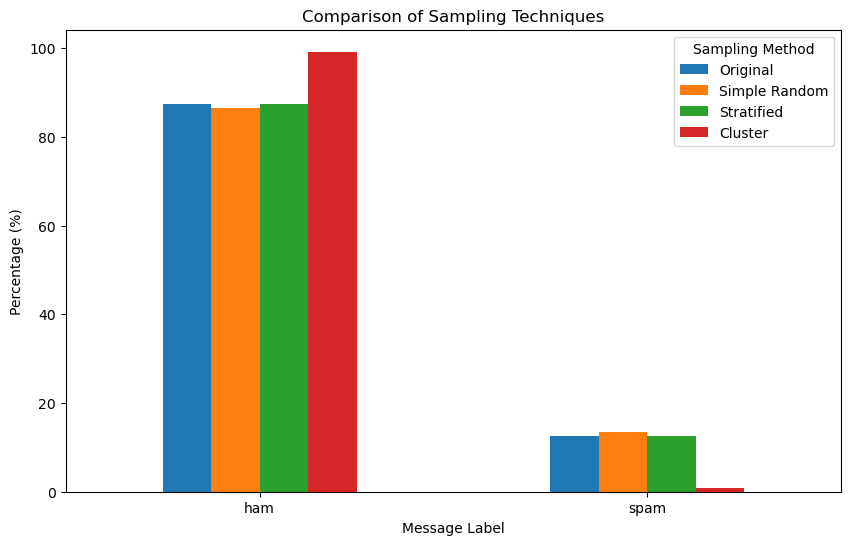

In [9]:
sampling_comparison = pd.DataFrame({
    'Original': df['label'].value_counts(normalize=True) * 100,
    'Simple Random': simple_random['label'].value_counts(normalize=True) * 100,
    'Stratified': stratified_sample['label'].value_counts(normalize=True) * 100,
    'Cluster': cluster_sample['label'].value_counts(normalize=True) * 100
})

print(sampling_comparison)

# Visualize comparison
sampling_comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Comparison of Sampling Techniques')
plt.ylabel('Percentage (%)')
plt.xlabel('Message Label')
plt.xticks(rotation=0)
plt.legend(title='Sampling Method')
plt.show()

In [10]:
# Feature 1: Character Count
df['char_count'] = df['message'].apply(len)

# Feature 2: Word Count
df['word_count'] = df['message'].apply(
    lambda x: len(x.split())
)

# Feature 3: Average Word Length
df['avg_word_length'] = df['message'].apply(
    lambda x: np.mean([len(word) for word in x.split()])
    if len(x.split()) > 0 else 0
)

# Feature 4: Digit Count
df['digit_count'] = df['message'].apply(
    lambda x: sum(char.isdigit() for char in x)
)

# Display the new features
df[[
    'message',
    'char_count',
    'word_count',
    'avg_word_length',
    'digit_count'
]].head()

,message,char_count,word_count,avg_word_length,digit_count
0,"Go until jurong point, crazy.. Available only ...",111,20,4.600000,0
1,Ok lar... Joking wif u oni...,29,6,4.000000,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,4.571429,25
3,U dun say so early hor... U c already then say...,49,11,3.545455,0
4,"Nah I don't think he goes to usf, he lives aro...",61,13,3.769231,0


                 char_count  word_count  avg_word_length  digit_count  \
char_count         1.000000    0.973858         0.084239     0.378848   
word_count         0.973858    1.000000        -0.067163     0.283588   
avg_word_length    0.084239   -0.067163         1.000000     0.229609   
digit_count        0.378848    0.283588         0.229609     1.000000   
label_numeric      0.379791    0.283920         0.242217     0.836894   

                 label_numeric  
char_count            0.379791  
word_count            0.283920  
avg_word_length       0.242217  
digit_count           0.836894  
label_numeric         1.000000  


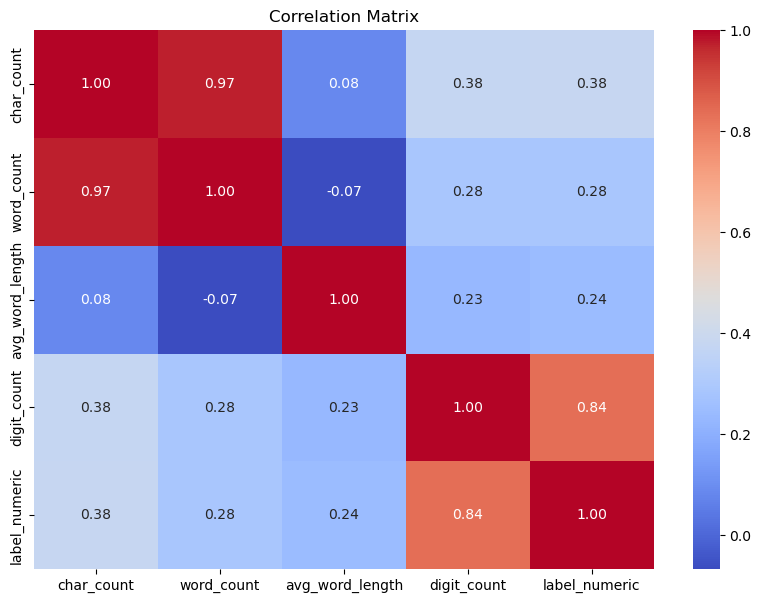

In [11]:
# Convert label into numerical values
df['label_numeric'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Select numerical features
numerical_features = [
    'char_count',
    'word_count',
    'avg_word_length',
    'digit_count',
    'label_numeric'
]

# Calculate correlation matrix
correlation_matrix = df[numerical_features].corr()

print(correlation_matrix)

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [12]:
print("Final Dataset Shape:", df.shape)

print("\nFinal Dataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Final Dataset Shape: (5169, 12)

Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5169 entries, 0 to 5168
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   label              5169 non-null   object 
 1   message            5169 non-null   object 
 2   lowercase_message  5169 non-null   object 
 3   no_punctuation     5169 non-null   object 
 4   cleaned_message    5169 non-null   object 
 5   message_length     5169 non-null   int64  
 6   cluster            5169 non-null   int64  
 7   char_count         5169 non-null   int64  
 8   word_count         5169 non-null   int64  
 9   avg_word_length    5169 non-null   float64
 10  digit_count        5169 non-null   int64  
 11  label_numeric      5169 non-null   int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 484.7+ KB

First 5 Rows:


,label,message,lowercase_message,no_punctuation,cleaned_message,message_length,cluster,char_count,word_count,avg_word_length,digit_count,label_numeric
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",go until jurong point crazy available only in ...,go until jurong point crazy available only in ...,111,3,111,20,4.600000,0,0
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni,29,0,29,6,4.000000,0,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,155,4,155,28,4.571429,25,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say,u dun say so early hor u c already then say,49,2,49,11,3.545455,0,0
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,nah i dont think he goes to usf he lives aroun...,61,2,61,13,3.769231,0,0



Missing Values:
label                0
message              0
lowercase_message    0
no_punctuation       0
cleaned_message      0
message_length       0
cluster              0
char_count           0
word_count           0
avg_word_length      0
digit_count          0
label_numeric        0
dtype: int64
